# 03 · Layer 2: patient co-reports

**Owner:** Sami
**Reads:** `nodes.csv`, openFDA adverse-event reports
**Writes:** `data/processed/layer2_edges.csv`, two figures in `outputs/`

Weight *w<sub>ij</sub>* = *N<sub>ij</sub>* / *E<sub>ij</sub>*, with *E<sub>ij</sub>* = *N<sub>i</sub>N<sub>j</sub>*/*N*. A pair is kept when *N<sub>ij</sub>* ≥ 5 and the lower 95% bound of log *w<sub>ij</sub>* is above 0.

The first run needs an openFDA API key and makes a few thousand requests (the notebook prints how many before it starts). Everything is cached in `data/raw/`.

In [1]:
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
REFERENCE = ROOT / "data" / "reference"
PROCESSED = ROOT / "data" / "processed"
OUTPUTS = ROOT / "outputs"

import os

from dotenv import load_dotenv

load_dotenv(ROOT / ".env")
API_KEY = os.getenv("OPENFDA_API_KEY", "")
print("API key found" if API_KEY else "No API key: add it to .env (see .env.example)")

API key found


In [2]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

sys.path.insert(0, str(ROOT / "notebooks"))
import figure_style as fs
import openfda_utils as fu

fs.apply()

In [3]:
MIN_SUPPORT = 5
CONF_LEVEL = 0.95        # two-sided interval for log w; rule 2 uses its lower end
TOTAL = "named"          # N in E_ij: "named" = reports with at least one recognised substance name, "all" = every report
EXACT_FOR_ALL = False    # True: one query per pair (n(n-1)/2 queries, several hours) instead of the short cut in Step 2
SPOT_CHECKS = 150        # pairs from the short cut that are counted again with an exact query
SAME_PRODUCT = 0.5       # flag a pair when this share of the rarer drug's reports also list the other drug

Z = norm.ppf(1 - (1 - CONF_LEVEL) / 2)
if not API_KEY:
    raise RuntimeError("This notebook needs an openFDA API key (the keyless limit is 1,000 requests a day): "
                       "put OPENFDA_API_KEY in .env, see .env.example.")

## Step 1 · Nodes, totals and the data snapshot

A report "lists drug *i*" when it carries any of the drug's `fda_names`, the same rule notebook 01 used for `n_reports`.

Every answer from openFDA states when the report database was last updated. The notebook collects these dates and stops at the end if it has seen more than one: all counts must come from one snapshot. For the same reason *N<sub>i</sub>* is counted again here and compared with `nodes.csv`.

In [4]:
nodes = pd.read_csv(PROCESSED / "nodes.csv", dtype={"rxcui": str})
n = len(nodes)
ing = nodes.ingredient.tolist()
names = [s.split("|") for s in nodes.fda_names]
clause = ["(" + fu.or_query(fu.SUB, nm) + ")" for nm in names]      # (name 1 OR name 2 ...)
node_of_name = {nm: i for i, ns in enumerate(names) for nm in ns}
assert len(node_of_name) == sum(len(ns) for ns in names), "an FDA name belongs to two nodes"

snapshots = set()

def ask(params, tag, slim=False):
    """One openFDA event query (cached); remembers the snapshot date of the answer."""
    resp = fu.openfda(RAW, API_KEY, "event", params, tag, slim=slim)
    if resp.get("meta", {}).get("last_updated"):
        snapshots.add(resp["meta"]["last_updated"])
    return resp

N_all = fu.total(ask({"limit": 1}, "N_all_reports", slim=True))
N_named = fu.total(ask({"search": "_exists_:patient.drug.openfda.substance_name", "limit": 1}, "N_named_reports", slim=True))
N = float(N_named if TOTAL == "named" else N_all)

# same query and cache tag as notebook 01, so nothing is fetched twice on the machine that ran it
N_i = np.array([fu.total(ask({"search": fu.or_query(fu.SUB, nm), "limit": 1}, f"N_{s[:40]}"))
                for nm, s in zip(names, nodes.fda_names)], dtype=float)
changed = int((N_i != nodes.n_reports).sum())
print(f"{n} drugs, {n * (n - 1) // 2:,} pairs. Reports: {N_all:,} in total, {N_named:,} with a recognised substance name; N = {N:,.0f}.")
print(f"Snapshot date(s) so far: {sorted(snapshots)}")
if changed:
    print(f"NOTE: {changed} of {n} report counts differ from nodes.csv (largest relative change "
          f"{np.max(np.abs(N_i / nodes.n_reports - 1)):.1%}). openFDA has updated the reports since notebook 01 ran. "
          "Layer 2 uses the counts fetched now; rerun notebook 01 if the ranking of the drugs should follow.")
else:
    print("All report counts equal nodes.csv.")

300 drugs, 44,850 pairs. Reports: 21,054,159 in total, 16,532,042 with a recognised substance name; N = 16,532,042.
Snapshot date(s) so far: ['2026-10-28']
All report counts equal nodes.csv.


## Step 2 · Reports that list both drugs

**Short cut.** One query per drug returns the substance names that occur most often in *its* reports, with counts (at most 1,000 names). If drug *j* has a single FDA name, its line in the list of drug *i* **is** *N<sub>ij</sub>*.

**Where it fails.** If drug *j* has several names (`METOPROLOL SUCCINATE`, `METOPROLOL TARTRATE`), the list gives one count per name and a report can carry both, so neither the sum nor the maximum is *N<sub>ij</sub>*. And the list stops after 1,000 names, so a missing name does not mean zero.

A pair is settled if the list of either drug gives its count. Every other pair gets one exact query (*reports listing i AND j*). Pairs that both lists settle are a free check: the two numbers must agree.

In [5]:
counts_ready = False          # set to True at the end of this cell; the file is only written if every check passed

def exact_pair(i, j):
    return fu.total(ask({"search": clause[i] + "+AND+" + clause[j], "limit": 1}, f"pair_{i}_{j}", slim=True))

def run_exact(pairs, what):
    print(f"{what}: {len(pairs):,} exact queries, up to {len(pairs) * 0.35 / 60:.0f} min if none is cached.")
    t0, out = time.time(), []
    for k, (i, j) in enumerate(pairs, 1):
        out.append(exact_pair(int(i), int(j)))
        if k % 1000 == 0:
            print(f"  {k:>6,} of {len(pairs):,}  ({(time.time() - t0) / 60:.1f} min)")
    return out

single = np.array([len(ns) == 1 for ns in names])
iu, ju = np.triu_indices(n, k=1)
n_ij = np.full((n, n), np.nan)
source = np.full((n, n), "", dtype=object)

if EXACT_FOR_ALL:
    n_ij[iu, ju] = run_exact(list(zip(iu, ju)), "All pairs")
    source[iu, ju] = "exact query"
else:
    from_list = np.full((n, n), np.nan)      # from_list[i, j] = N_ij read from the list of drug i
    cut = 0
    for i in range(n):
        res = ask({"search": clause[i], "count": fu.SUB, "limit": 1000}, f"colist_{ing[i]}").get("results", [])
        seen = {r["term"]: r["count"] for r in res}
        cut += len(res) >= 1000
        for j in np.flatnonzero(single):
            if j != i:
                if names[j][0] in seen:
                    from_list[i, j] = seen[names[j][0]]
                elif len(res) < 1000:        # complete list: a missing name means zero
                    from_list[i, j] = 0
    a, b = from_list[iu, ju], from_list[ju, iu]
    both = ~np.isnan(a) & ~np.isnan(b)
    bad = both & (a != b)
    print(f"{n} lists read, {cut} cut off at 1,000 names. {both.sum():,} pairs settled by both lists: {int(bad.sum())} disagree.")
    if bad.any():
        k = int(np.argmax(np.where(both, np.abs(a - b), 0)))
        raise RuntimeError(f"The lists are not exact (e.g. {ing[iu[k]]} / {ing[ju[k]]}: {a[k]:.0f} and {b[k]:.0f}). "
                           "Set EXACT_FOR_ALL = True and run again.")
    settled = ~np.isnan(a) | ~np.isnan(b)
    n_ij[iu, ju] = np.where(~np.isnan(a), a, b)
    source[iu[settled], ju[settled]] = "list"
    rest = list(zip(iu[~settled], ju[~settled]))
    n_ij[iu[~settled], ju[~settled]] = run_exact(rest, "Pairs the lists cannot settle") if rest else []
    source[iu[~settled], ju[~settled]] = "exact query"

    rng = np.random.default_rng(636)
    pool = np.flatnonzero(settled)
    sample = rng.choice(pool, size=min(SPOT_CHECKS, len(pool)), replace=False)
    wrong = [k for k in sample if exact_pair(int(iu[k]), int(ju[k])) != n_ij[iu[k], ju[k]]]
    if wrong:
        raise RuntimeError(f"{len(wrong)} of {len(sample)} spot checks disagree with the lists "
                           f"(e.g. {ing[iu[wrong[0]]]} / {ing[ju[wrong[0]]]}). Set EXACT_FOR_ALL = True and run again.")
    print(f"Spot check: {len(sample)} list-settled pairs counted again with an exact query, all identical.")

assert not np.isnan(n_ij[iu, ju]).any()
n_ij = np.nan_to_num(n_ij)
n_ij = n_ij + n_ij.T
assert (n_ij <= np.minimum.outer(N_i, N_i)).all(), "a pair has more joint reports than one of its drugs has reports"
assert len(snapshots) == 1, f"answers come from different snapshots {sorted(snapshots)}: delete data/raw/openfda/ and rerun"
counts_ready = True
print(f"Pair counts ready ({pd.Series(source[iu, ju]).value_counts().to_dict()}). Snapshot: {sorted(snapshots)[0]}. Requests: {fu.STATS}")

300 lists read, 300 cut off at 1,000 names. 21,527 pairs settled by both lists: 0 disagree.
Pairs the lists cannot settle: 5,089 exact queries, up to 30 min if none is cached.
   1,000 of 5,089  (14.8 min)
   2,000 of 5,089  (29.8 min)
   3,000 of 5,089  (45.8 min)
   4,000 of 5,089  (60.1 min)
   5,000 of 5,089  (75.1 min)
Spot check: 150 list-settled pairs counted again with an exact query, all identical.
Pair counts ready ({'list': 39761, 'exact query': 5089}). Snapshot: 2026-10-28. Requests: {'requests': 5541, 'cached': 300}


## Step 3 · Observed against expected

If two drugs were reported independently, *E<sub>ij</sub>* = *N<sub>i</sub>N<sub>j</sub>*/*N* reports would list both. The weight *w<sub>ij</sub>* = *N<sub>ij</sub>*/*E<sub>ij</sub>* is 1 for "as often as chance" and 3 for three times as often.

The standard error of log *w<sub>ij</sub>* (delta method on the 2×2 table drug *i* yes/no × drug *j* yes/no) is

$$\operatorname{se} = \sqrt{\frac{1}{N_{ij}} - \frac{1}{N_i} - \frac{1}{N_j} + \frac{2N_{ij}}{N_iN_j} - \frac{1}{N}}$$

which is close to $1/\sqrt{N_{ij}}$ for a rare pair. The interval is log *w* ± *z*·se. The first cell checks by simulation that it covers the true ratio 95% of the time.

In [6]:
def log_w_se(n_ij, n_i, n_j, N):
    """log(observed / expected) and its standard error; NaN where there is no joint report."""
    with np.errstate(divide="ignore", invalid="ignore"):
        lw = np.log(n_ij * N / (n_i * n_j))
        var = 1 / n_ij - 1 / n_i - 1 / n_j + 2 * n_ij / (n_i * n_j) - 1 / N
    ok = n_ij > 0
    return np.where(ok, lw, np.nan), np.where(ok, np.sqrt(np.clip(var, 0, None)), np.nan)

sim = np.random.default_rng(636)
for what, N_sim, p_i, p_j, w_true in [("rare pair, about 6 joint reports", 2_000_000, 0.0005, 0.0006, 10.0),
                                      ("rare pair, about 50 joint reports", 2_000_000, 0.004, 0.003, 2.0),
                                      ("two very common drugs", 200_000, 0.2, 0.3, 1.3)]:
    p = w_true * p_i * p_j
    c = sim.multinomial(N_sim, [p, p_i - p, p_j - p, 1 - p_i - p_j + p], size=20_000).astype(float)
    lw, se = log_w_se(c[:, 0], c[:, 0] + c[:, 1], c[:, 0] + c[:, 2], N_sim)
    ok = ~np.isnan(lw)
    print(f"{what:35s} interval covers the true w in {np.mean(np.abs(lw[ok] - np.log(w_true)) <= 1.96 * se[ok]):.1%} of 20,000 simulations")

rare pair, about 6 joint reports    interval covers the true w in 96.4% of 20,000 simulations
rare pair, about 50 joint reports   interval covers the true w in 95.2% of 20,000 simulations
two very common drugs               interval covers the true w in 94.9% of 20,000 simulations


In [7]:
assert counts_ready, "the counting step above stopped with an error: fix that first, nothing is written until it passes"
E = np.outer(N_i, N_i) / N
log_w, se = log_w_se(n_ij, N_i[:, None], N_i[None, :], N)
w = n_ij / E
lcb, ucb = log_w - Z * se, log_w + Z * se
with np.errstate(invalid="ignore"):
    passes = (n_ij >= MIN_SUPPORT) & (lcb > 0)
overlap = n_ij / np.minimum.outer(N_i, N_i)          # share of the rarer drug's reports that also list the other drug

layer2 = pd.DataFrame({
    "i_id": iu, "j_id": ju, "n_ij": n_ij[iu, ju].astype(int), "n_i": N_i[iu].astype(int), "n_j": N_i[ju].astype(int),
    "e_ij": E[iu, ju], "w_ij": w[iu, ju], "log_w_lcb": lcb[iu, ju], "log_w_ucb": ucb[iu, ju],
    "passes_filter": passes[iu, ju].astype(int), "overlap": overlap[iu, ju], "count_source": source[iu, ju]})
layer2.to_csv(PROCESSED / "layer2_edges.csv", index=False, float_format="%.6g")

# one pair, step by step
if {"warfarin", "furosemide"} <= set(ing):
    i, j = sorted((ing.index("warfarin"), ing.index("furosemide")))
else:
    i, j = layer2[layer2.passes_filter == 1].sort_values("n_ij", ascending=False).iloc[0][["i_id", "j_id"]].astype(int)
print(f"Worked example: {ing[i]} and {ing[j]}")
print(f"  N_i = {N_i[i]:,.0f}, N_j = {N_i[j]:,.0f}, both: N_ij = {n_ij[i, j]:,.0f}")
print(f"  expected E = N_i N_j / N = {E[i, j]:,.1f};  w = {w[i, j]:.2f};  log w = {log_w[i, j]:.3f} ± {Z:.2f} × {se[i, j]:.4f}")
print(f"  interval for w: {np.exp(lcb[i, j]):.2f} to {np.exp(ucb[i, j]):.2f}  →  {'edge' if passes[i, j] else 'no edge'}")

m = int(layer2.passes_filter.sum())
print(f"\n{len(layer2):,} pairs saved; {(layer2.n_ij > 0).mean():.0%} share a report, {(layer2.n_ij >= MIN_SUPPORT).sum():,} have "
      f"N_ij ≥ {MIN_SUPPORT}, {m:,} pass both rules (density {m / len(layer2):.3f}).")

Worked example: furosemide and warfarin
  N_i = 403,546, N_j = 126,980, both: N_ij = 25,233
  expected E = N_i N_j / N = 3,099.6;  w = 8.14;  log w = 2.097 ± 1.96 × 0.0055
  interval for w: 8.05 to 8.23  →  edge

44,850 pairs saved; 99% share a report, 43,714 have N_ij ≥ 5, 22,575 pass both rules (density 0.503).


## Checks

1. **Top pairs.** The most co-reported pairs should be familiar combinations. Pairs flagged `same product?` are mostly two ingredients of one product (the reports list each ingredient of a combination product by its own name), not two drugs taken together. They are real co-reports but poor interaction candidates; notebook 05 sets them aside.
2. **Observed against expected.** Pairs on the line are reported together as often as chance predicts.
3. **Thresholds.** The number of edges should not hinge on the exact cut-offs.

In [8]:
show = layer2.assign(drug_i=[ing[k] for k in iu], drug_j=[ing[k] for k in ju],
                     w=layer2.w_ij.round(2), expected=layer2.e_ij.round(1), lcb=layer2.log_w_lcb.round(2),
                     same_product=np.where(layer2.overlap >= SAME_PRODUCT, "same product?", ""))
cols = ["drug_i", "drug_j", "n_ij", "expected", "w", "lcb", "same_product"]
print("Most joint reports:")
print(show.sort_values(["n_ij", "i_id", "j_id"], ascending=[False, True, True])[cols].head(12).to_string(index=False))
print("\nStrongest signals (highest lower bound of log w):")
print(show[show.passes_filter == 1].sort_values(["log_w_lcb", "i_id", "j_id"], ascending=[False, True, True])[cols].head(15).to_string(index=False))
print(f"\n{int(((layer2.overlap >= SAME_PRODUCT) & (layer2.passes_filter == 1)).sum())} edges are flagged as 'same product?' "
      f"(overlap ≥ {SAME_PRODUCT}).")
chance = (1 - CONF_LEVEL) / 2 * (layer2.n_ij >= MIN_SUPPORT).sum()
print(f"If no two drugs were related, rule 2 alone would still pass about {chance:,.0f} pairs; {m:,} pass.")

Most joint reports:
          drug_i           drug_j   n_ij  expected     w  lcb  same_product
   acetaminophen  diphenhydramine 297637   15546.0 19.15 2.95 same product?
   acetaminophen        ibuprofen 293809   19242.0 15.27 2.72 same product?
       ibuprofen  diphenhydramine 292655   13069.5 22.39 3.11 same product?
   acetaminophen dextromethorphan 275493   11677.5 23.59 3.16 same product?
 diphenhydramine dextromethorphan 266616    7931.5 33.61 3.51 same product?
       ibuprofen dextromethorphan 263395    9817.3 26.83 3.29 same product?
dextromethorphan       doxylamine 261187    5048.9 51.73 3.94 same product?
 diphenhydramine       doxylamine 260976    6721.4 38.83 3.66 same product?
   acetaminophen       doxylamine 260916    9895.9 26.37 3.27 same product?
       ibuprofen       doxylamine 260581    8319.4 31.32 3.44 same product?
   acetaminophen    phenylephrine 229150    9949.8 23.03 3.13 same product?
   acetaminophen      guaifenesin 172041    7692.1 22.37 3.10 same p

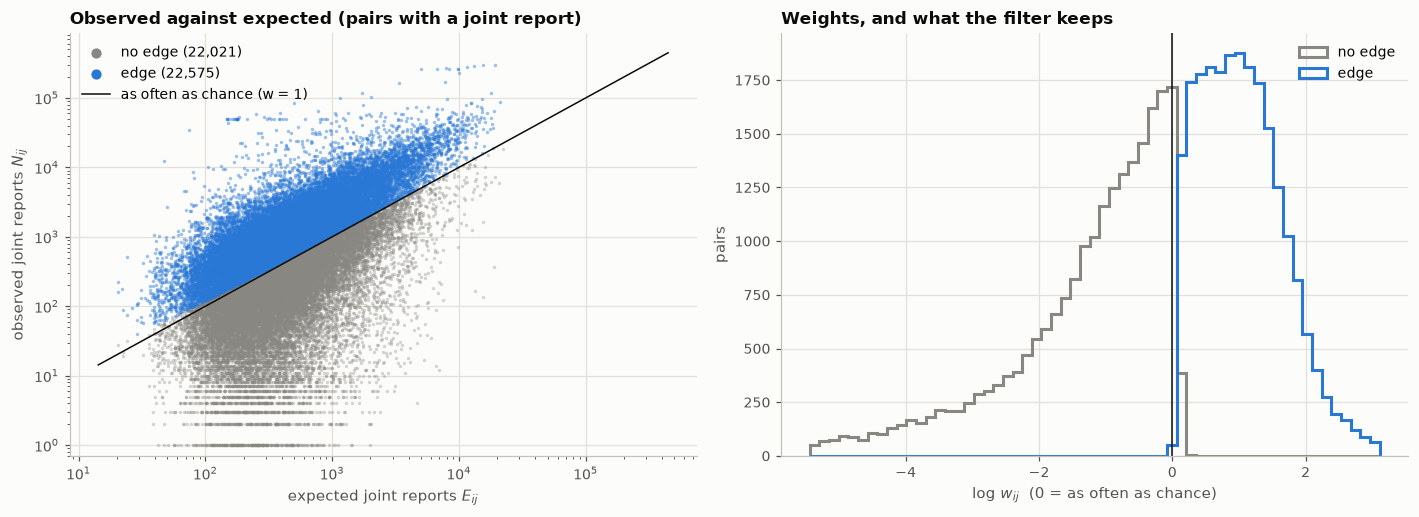

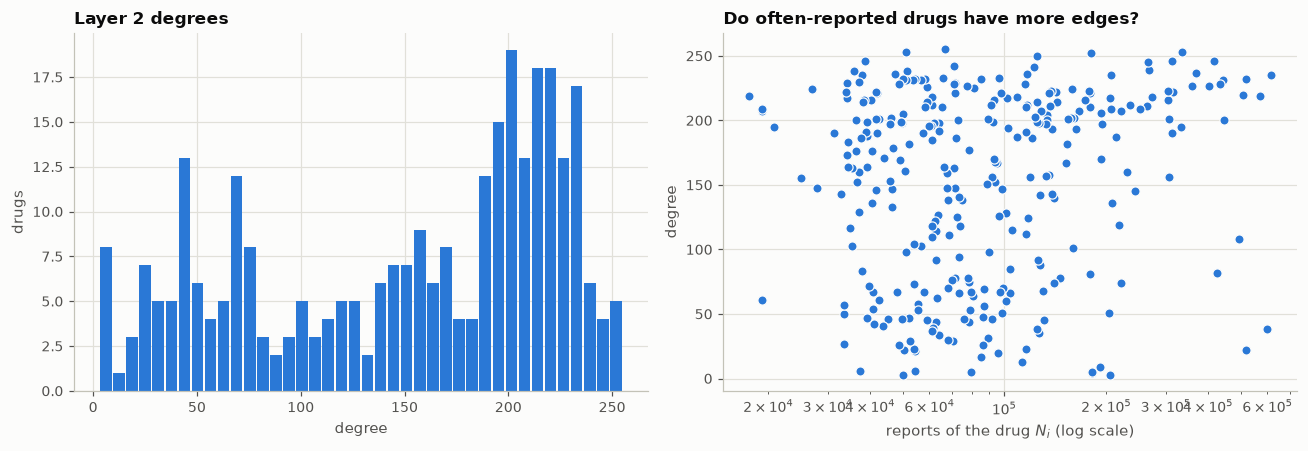

0 drugs have no Layer 2 edge. Correlation of degree with log N_i: 0.14


In [9]:
seen = layer2[layer2.n_ij > 0]
kept, dropped = seen[seen.passes_filter == 1], seen[seen.passes_filter == 0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
lo, hi = max(1e-2, seen.e_ij.min() * 0.7), max(seen.e_ij.max(), seen.n_ij.max()) * 1.5
ax.scatter(dropped.e_ij, dropped.n_ij, s=5, color=fs.MUTED, alpha=0.35, linewidths=0, rasterized=True, label=f"no edge ({len(dropped):,})")
ax.scatter(kept.e_ij, kept.n_ij, s=5, color=fs.COLORS[0], alpha=0.45, linewidths=0, rasterized=True, label=f"edge ({len(kept):,})")
ax.plot([lo, hi], [lo, hi], color=fs.INK, lw=1, label="as often as chance (w = 1)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(bottom=0.7)
ax.set_xlabel("expected joint reports $E_{ij}$"); ax.set_ylabel("observed joint reports $N_{ij}$")
ax.set_title("Observed against expected (pairs with a joint report)")
for h in ax.legend(loc="upper left", markerscale=3).legend_handles:
    h.set_alpha(1)
ax = axes[1]
lw_seen = np.log(seen.w_ij)
bins = np.linspace(np.percentile(lw_seen, 0.5), np.percentile(lw_seen, 99.5), 60)
ax.hist(np.log(dropped.w_ij), bins=bins, histtype="step", linewidth=2, color=fs.MUTED, label="no edge")
ax.hist(np.log(kept.w_ij), bins=bins, histtype="step", linewidth=2, color=fs.COLORS[0], label="edge")
ax.axvline(0, color=fs.INK, lw=1)
ax.set_xlabel("log $w_{ij}$  (0 = as often as chance)"); ax.set_ylabel("pairs"); ax.set_title("Weights, and what the filter keeps")
ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(OUTPUTS / "03_layer2_observed_expected.png"); plt.show()

A2 = np.where(passes, w, 0.0)
degree = (A2 > 0).sum(1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.arange(degree.min() - 0.5, degree.max() + 1.5) if degree.max() - degree.min() <= 60 else 40
axes[0].hist(degree, bins=bins, color=fs.COLORS[0], rwidth=0.88)
axes[0].xaxis.get_major_locator().set_params(integer=True); axes[1].yaxis.get_major_locator().set_params(integer=True)
axes[0].set_xlabel("degree"); axes[0].set_ylabel("drugs"); axes[0].set_title("Layer 2 degrees")
axes[1].scatter(N_i, degree, s=36, color=fs.COLORS[0], edgecolor=fs.SURFACE, linewidth=0.8)
axes[1].set_xscale("log"); axes[1].set_xlabel("reports of the drug $N_i$ (log scale)"); axes[1].set_ylabel("degree")
axes[1].set_title("Do often-reported drugs have more edges?")
fig.tight_layout(); fig.savefig(OUTPUTS / "03_layer2_degrees.png"); plt.show()
print(f"{int((degree == 0).sum())} drugs have no Layer 2 edge. Correlation of degree with log N_i: {np.corrcoef(np.log(N_i), degree)[0, 1]:.2f}")

In [10]:
lw_all, se_all = log_w[iu, ju], se[iu, ju]
grid = pd.DataFrame({f"{c:.1%} interval": {f"N_ij ≥ {s}": int(((layer2.n_ij >= s) & (lw_all - norm.ppf(1 - (1 - c) / 2) * se_all > 0)).sum())
                                            for s in (3, 5, 10, 20)} for c in (0.90, 0.95, 0.99, 0.999)})
print("Edges under other thresholds:")
print(grid.to_string())
print(f"\nChosen: N_ij ≥ {MIN_SUPPORT}, {CONF_LEVEL:.0%} interval.  Total N used: {N:,.0f} ({TOTAL}).")

Edges under other thresholds:
           90.0% interval  95.0% interval  99.0% interval  99.9% interval
N_ij ≥ 3            22742           22575           22218           21853
N_ij ≥ 5            22742           22575           22218           21853
N_ij ≥ 10           22742           22575           22218           21853
N_ij ≥ 20           22742           22575           22218           21853

Chosen: N_ij ≥ 5, 95% interval.  Total N used: 16,532,042 (named).
